# Day 3: Filtering & Convolutions
Today we will cover:
- Why Filtering Matters
- Convolution Basics
- Common Filters (Blur, Sharpen, Edge Detection)
- Edge Detection (Canny)
- Applications
- Lab Exercise
- Mini-Project

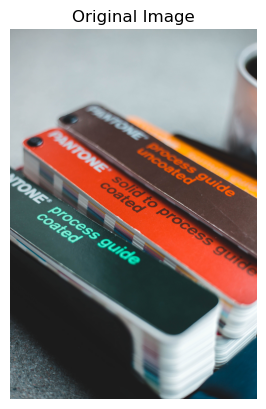

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load image
img = cv2.imread('sample.jpg')   # replace with your image file
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis('off')
plt.show()

## Why Filtering Matters
- Enhances or suppresses features.
- Used for blurring, sharpening, and edge detection.
- Foundation of Convolutional Neural Networks (CNNs).

## Convolution Basics
- Kernel = small matrix applied to an image.
- Sliding window computes weighted sum.
- Produces a feature map highlighting patterns.

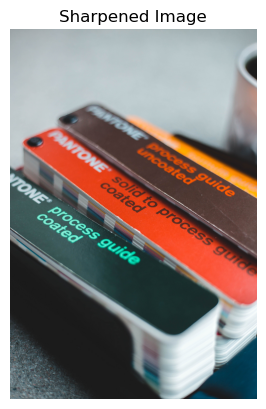

In [2]:
kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])  # sharpening kernel
sharp = cv2.filter2D(img, -1, kernel)

plt.imshow(cv2.cvtColor(sharp, cv2.COLOR_BGR2RGB))
plt.title("Sharpened Image")
plt.axis('off')
plt.show()

## Common Filters
- Blur (average, Gaussian)
- Sharpen
- Edge detection (Sobel, Laplacian)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-6037.0..5772.0].


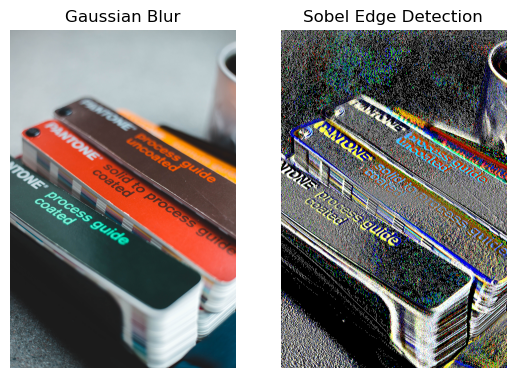

In [3]:
blur = cv2.GaussianBlur(img, (5,5), 0)
edges_sobel = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=5)

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(blur, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Blur")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(edges_sobel, cmap='gray')
plt.title("Sobel Edge Detection")
plt.axis('off')

plt.show()

## Canny Edge Detection
- Combines gradient + thresholding.
- Produces clean edge maps.

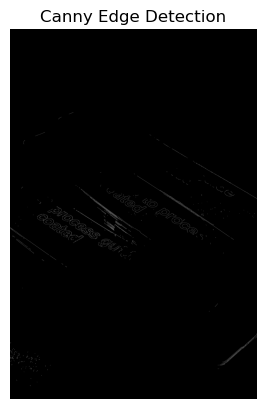

In [4]:
edges_canny = cv2.Canny(img, 100, 200)

plt.imshow(edges_canny, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis('off')
plt.show()

## Applications of Filtering
- Medical imaging (tumor boundaries)
- Document scanning
- Autonomous driving (lane detection)

## Lab Exercise
- Apply blur, sharpen, and edge detection.
- Compare outputs side by side.

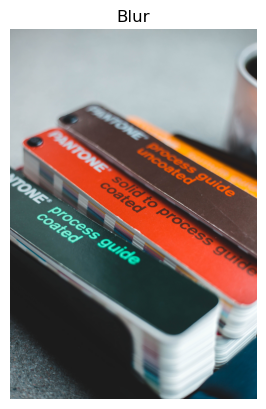

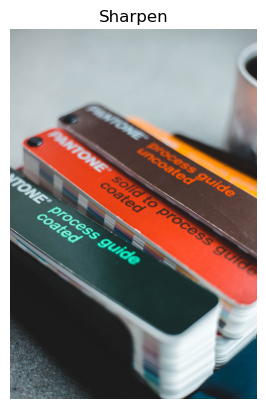

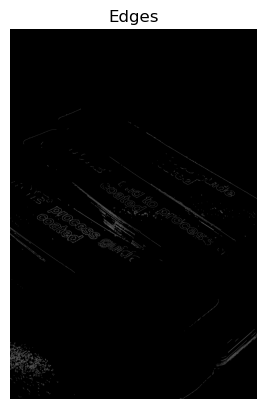

In [5]:
filters = {
    "blur": cv2.blur(img, (5,5)),
    "sharpen": cv2.filter2D(img, -1, kernel),
    "edges": cv2.Canny(img, 50, 150)
}

for name, output in filters.items():
    plt.figure()
    plt.imshow(output if name=="edges" else cv2.cvtColor(output, cv2.COLOR_BGR2RGB),
               cmap='gray' if name=="edges" else None)
    plt.title(name.capitalize())
    plt.axis('off')
    plt.show()

## Mini‑Project: Edge-Based Object Detector
- Input: photo of simple shapes.
- Output: contours + labels.

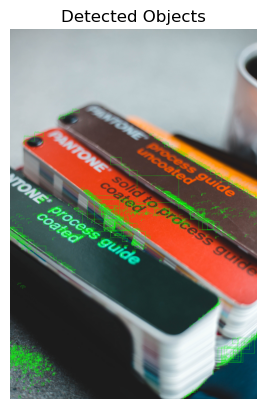

In [6]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150)
contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

img_contours = img.copy()
for i, cnt in enumerate(contours):
    x,y,w,h = cv2.boundingRect(cnt)
    cv2.rectangle(img_contours, (x,y), (x+w,y+h), (0,255,0), 2)
    cv2.putText(img_contours, f"Obj{i+1}", (x,y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 1)

plt.imshow(cv2.cvtColor(img_contours, cv2.COLOR_BGR2RGB))
plt.title("Detected Objects")
plt.axis('off')
plt.show()